# Expiry Pyramid — Strategy Overview & Validation

This notebook explains the Expiry Pyramid signal in plain language, shows
the feature engineering behind it, and reports its validated performance
honestly — including what's genuinely uncertain about it.

**Data disclosure.** This notebook runs on `data/sample/sample_features.csv`
only: a seeded random sample of **290 of the 713** rows in the full
engineered feature table, drawn across the complete 2023-2025 date range.
That 713-row table is itself derived from **2,114 raw snapshot files**
(paired 15:20/09:55 option-chain captures) — neither the raw snapshots, the
full feature table, nor the trained production model are published in this
repository. See `data/sample/NOTE.md` for the exact disclosure text.

As with the sibling `datashots` project, every figure below is labeled as
one of:

- **Computed from the sample** — run live, in this notebook, on the 290 rows.
- **Reconstructed / documented** — the random 290-row sample has no valid
  chronological order (it's a scattered subset of days), so anything that
  depends on time — the walk-forward validation accuracy, the annualized
  return — cannot be honestly recomputed from it. Those numbers come from
  the project's own walk-forward evaluation report and are labeled as such,
  never blurred with what's actually computed here.
- **Illustrative / schematic** — a diagram of the method itself, not a
  data-driven result.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)

DATA_PATH = Path("../data/sample/sample_features.csv")
ASSETS_DIR = Path("../assets")
ASSETS_DIR.mkdir(exist_ok=True, parents=True)

# --- Validated colorblind-safe palette (same as the datashots notebook) ----
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
MAGENTA, GREEN, VIOLET, RED = "#e87ba4", "#008300", "#4a3aa7", "#e34948"

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE_GRAY = "#c3c2b7"

UP_COLOR = BLUE
DOWN_COLOR = RED
HIGHLIGHT_COLOR = AQUA

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE_GRAY,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.titlecolor": INK,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
})


def style_axes(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.6)
    ax.set_axisbelow(True)
    return ax


_SAVED_FIGS = []


def save(fig, name):
    path = ASSETS_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    _SAVED_FIGS.append((name, str(path)))
    plt.show()
    print(f"saved {path}")


def wilson_ci(k, n, z=1.959963985):
    phat = k / n
    denom = 1 + z**2 / n
    center = phat + z**2 / (2 * n)
    margin = z * np.sqrt(phat * (1 - phat) / n + z**2 / (4 * n**2))
    return (center - margin) / denom, phat, (center + margin) / denom


print("Setup complete.")

Setup complete.


## Objective

The Expiry Pyramid strategy uses the overnight shift in NIFTY options
positioning — measured from the previous day's close through the next
morning — to predict which way NIFTY is more likely to move during that
day's 10:00 AM to 3:00 PM session. The idea: if call writers, put writers,
and net delta across the option chain are all shifting the same direction
overnight, that shift itself carries information about the next session's
likely direction.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
FEATURE_COLS = [c for c in df.columns if c not in ("date", "spot_1000", "spot_1500", "move_pts", "label")]
X = df[FEATURE_COLS].fillna(0.0)
y = df["label"]

print(f"Loaded {len(df)} rows, {len(FEATURE_COLS)} features from {DATA_PATH}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Class balance: {y.mean()*100:.1f}% bullish sessions, {(1-y.mean())*100:.1f}% bearish")

Loaded 290 rows, 34 features from ..\data\sample\sample_features.csv
Date range: 2023-01-03 to 2025-12-31
Class balance: 50.0% bullish sessions, 50.0% bearish


## Approach: three-tier snapshot differencing

Two snapshots of the option chain are captured each trading day: one at
**15:20** (previous day's close) and one at **09:55** (this morning, just
before the 10:00 entry window). Each snapshot covers **three expiry
tiers** — current week, next week, and the far week — and records, per
tier: total call/put open interest, put-call ratio, OI-weighted net delta,
and IV skew.

The **change** between the 15:20 and 09:55 snapshot, per tier, produces 11
delta-features (PCR before/after/change, call/put OI % change, OI-shift,
IV-skew before/after/change, delta-change, vega-change) × 3 tiers = 33
features, plus one shared `overnight_move_pct` = **34 features** total.
This is the same design the production classifier (`ml_direction.py`)
trains on.

saved ..\assets\fig01_approach_schematic.png


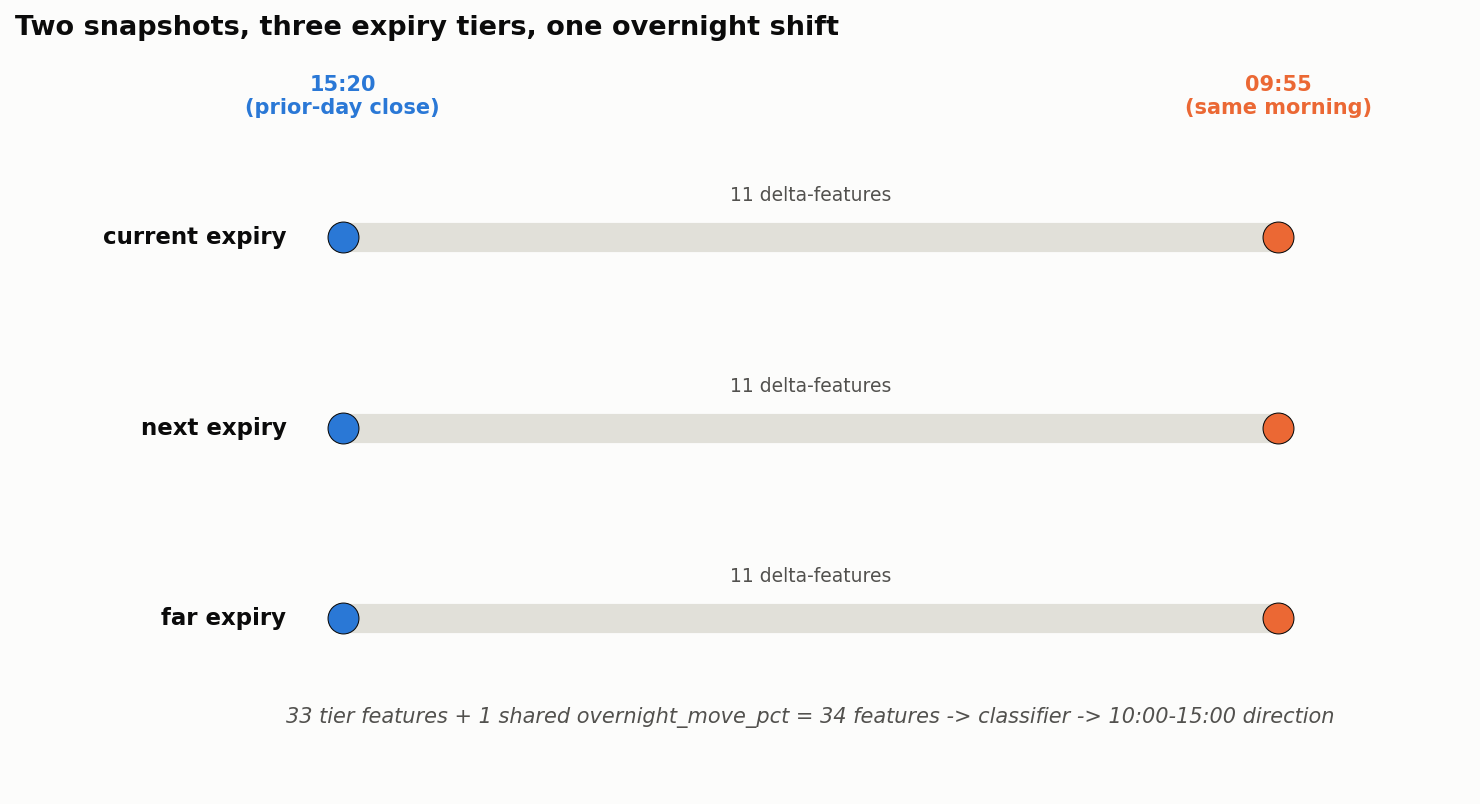

In [3]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axis("off")

tiers = ["current", "next", "far"]
y_positions = [2, 1, 0]
for tier, ypos in zip(tiers, y_positions):
    ax.plot([0, 1], [ypos, ypos], color=GRID, linewidth=14, solid_capstyle="round", zorder=1)
    ax.scatter([0], [ypos], s=220, color=BLUE, zorder=2, edgecolor=INK, linewidth=0.5)
    ax.scatter([1], [ypos], s=220, color=ORANGE, zorder=2, edgecolor=INK, linewidth=0.5)
    ax.text(-0.06, ypos, f"{tier} expiry", ha="right", va="center", fontsize=11, fontweight="bold")
    ax.text(0.5, ypos + 0.22, "11 delta-features", ha="center", va="center", fontsize=9, color=INK2)

ax.text(0, 2.65, "15:20\n(prior-day close)", ha="center", fontsize=10, color=BLUE, fontweight="bold")
ax.text(1, 2.65, "09:55\n(same morning)", ha="center", fontsize=10, color=ORANGE, fontweight="bold")
ax.text(0.5, -0.55, "33 tier features + 1 shared overnight_move_pct = 34 features -> classifier -> 10:00-15:00 direction",
        ha="center", fontsize=10, color=INK2, style="italic")

ax.set_xlim(-0.35, 1.2)
ax.set_ylim(-0.9, 3.0)
ax.set_title("Two snapshots, three expiry tiers, one overnight shift", loc="left")
fig.tight_layout()
save(fig, "fig01_approach_schematic")

**What this shows.** This is a schematic of the method, not a data-driven
result — it illustrates why the feature count is 34 (11 × 3 tiers + 1
shared feature) and where in the day the two snapshots fall.

## Figure 2 — Dataset overview

*Computed from the sample.*

saved ..\assets\fig02_dataset_overview.png


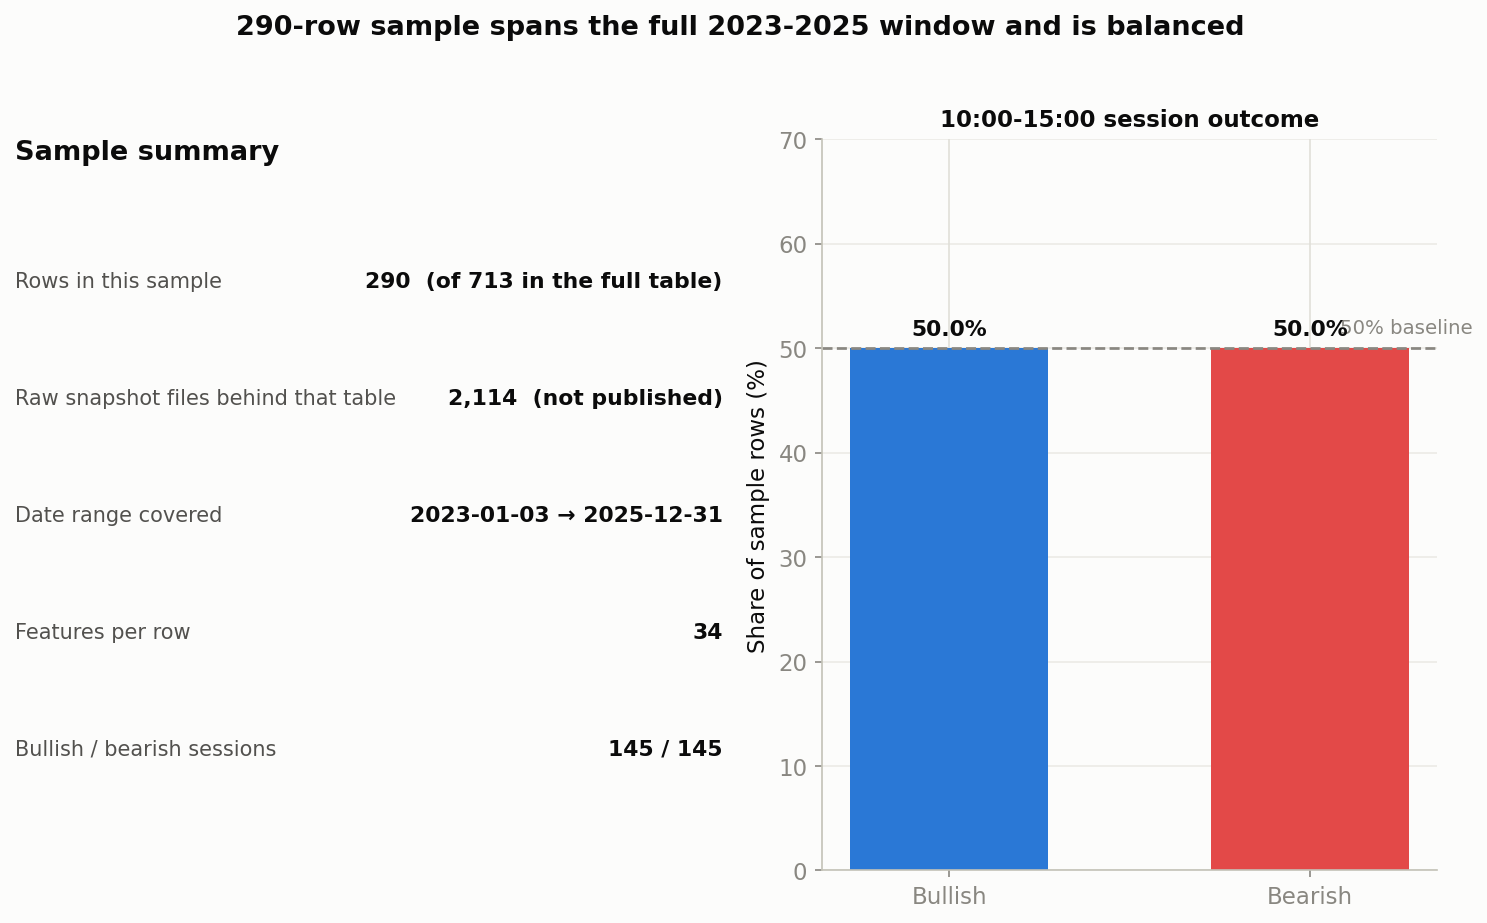

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6), gridspec_kw={"width_ratios": [1.15, 1]})
fig.suptitle("290-row sample spans the full 2023-2025 window and is balanced",
             fontsize=13, fontweight="bold", y=1.02)

ax = axes[0]
ax.axis("off")
facts = [
    ("Rows in this sample", f"{len(df)}  (of 713 in the full table)"),
    ("Raw snapshot files behind that table", "2,114  (not published)"),
    ("Date range covered", f"{df['date'].min().date()} \u2192 {df['date'].max().date()}"),
    ("Features per row", f"{len(FEATURE_COLS)}"),
    ("Bullish / bearish sessions", f"{int(y.sum())} / {int((1 - y).sum())}"),
]
ax.text(0, 1.0, "Sample summary", fontsize=13, fontweight="bold", color=INK, transform=ax.transAxes, va="top")
for i, (label, value) in enumerate(facts):
    ypos = 0.82 - i * 0.16
    ax.text(0, ypos, label, fontsize=10, color=INK2, transform=ax.transAxes, va="top")
    ax.text(1.0, ypos, value, fontsize=10.5, color=INK, fontweight="bold", transform=ax.transAxes, va="top", ha="right")

ax2 = style_axes(axes[1])
shares = [y.mean() * 100, (1 - y.mean()) * 100]
bars = ax2.bar(["Bullish", "Bearish"], shares, color=[UP_COLOR, DOWN_COLOR], width=0.55)
ax2.axhline(50, color=MUTED, linestyle="--", linewidth=1.3)
ax2.text(1.45, 51, "50% baseline", color=MUTED, fontsize=9.5, va="bottom", ha="right")
for b, s in zip(bars, shares):
    ax2.text(b.get_x() + b.get_width() / 2, s + 1.2, f"{s:.1f}%", ha="center", fontsize=10.5, fontweight="bold", color=INK)
ax2.set_ylim(0, 70)
ax2.set_ylabel("Share of sample rows (%)")
ax2.set_title("10:00-15:00 session outcome", fontsize=11, fontweight="bold")

fig.tight_layout()
save(fig, "fig02_dataset_overview")

**What this shows.** The sample stays almost exactly balanced (50/50)
across the full study window, so the figures below reflect the underlying
data rather than an artifact of a skewed subset.

## Figure 3 — Feature distributions by session outcome

*Computed from the sample.* The 8 features an XGBoost classifier relies on
most (by gain), split by whether the session that followed was bullish or
bearish.

saved ..\assets\fig03_feature_distributions.png


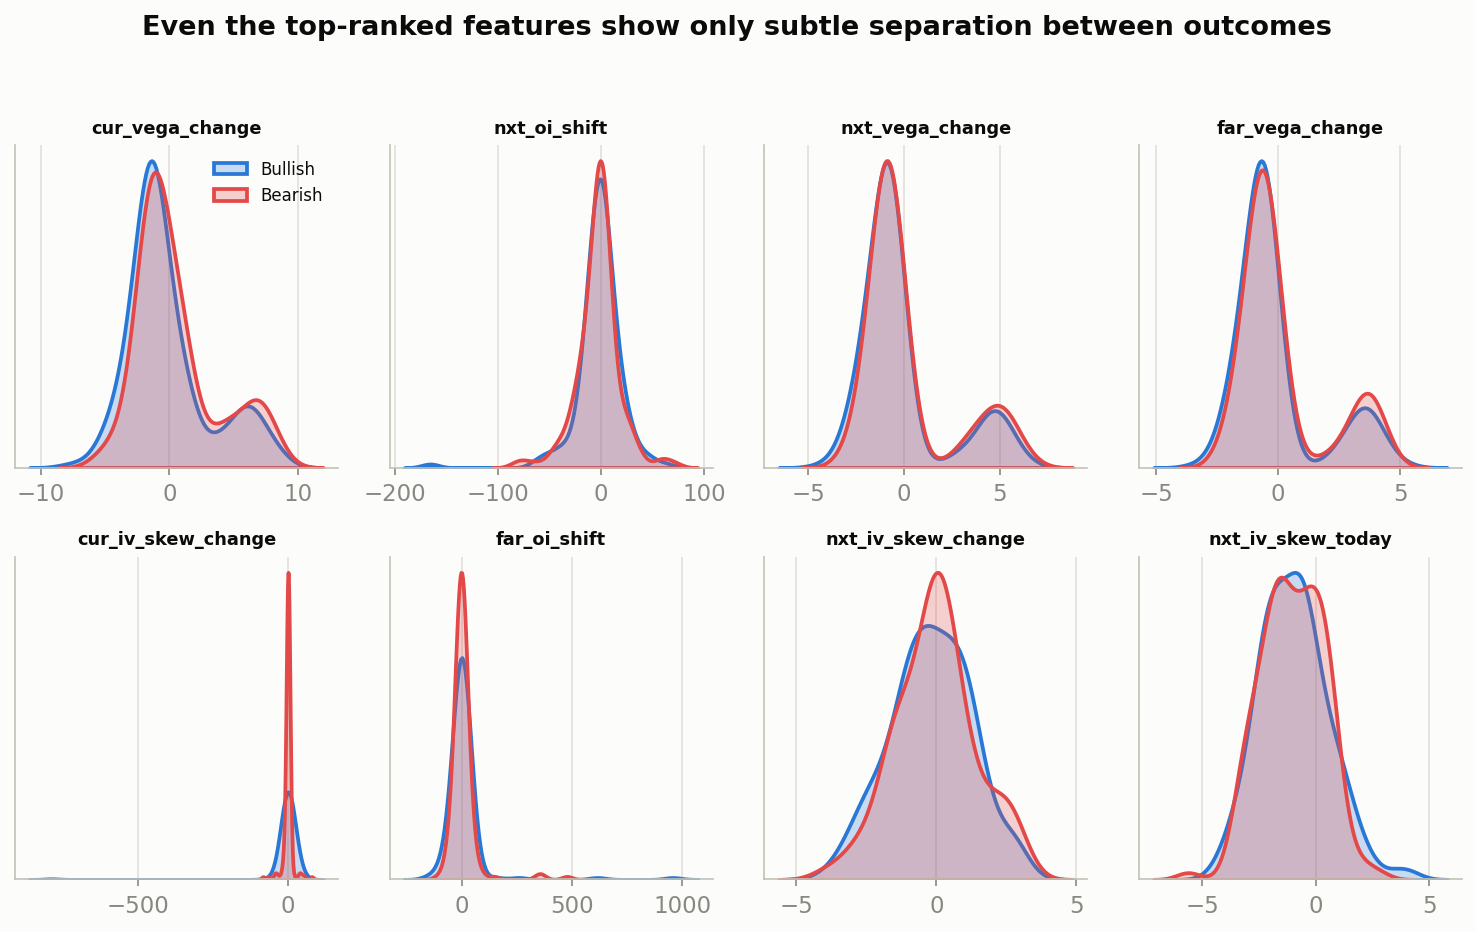

In [5]:
_imp_clf = XGBClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9, random_state=SEED,
    eval_metric="logloss", importance_type="gain",
).fit(X, y)
gain_importance = pd.Series(_imp_clf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
top8 = gain_importance.head(8).index.tolist()

fig, axes = plt.subplots(2, 4, figsize=(10, 6))
for ax, feat in zip(axes.ravel(), top8):
    ax = style_axes(ax)
    for cls, color, label in [(1, UP_COLOR, "Bullish"), (0, DOWN_COLOR, "Bearish")]:
        vals = X.loc[y == cls, feat].dropna()
        sns.kdeplot(vals, ax=ax, color=color, fill=True, alpha=0.25, linewidth=1.8, label=label)
    ax.set_title(feat, fontsize=8.5)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks([])

axes.ravel()[0].legend(fontsize=8, frameon=False, loc="upper right")
fig.suptitle("Even the top-ranked features show only subtle separation between outcomes",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "fig03_feature_distributions")

**What this shows.** The bullish and bearish distributions overlap
substantially even for the features the model ranks highest — there is no
feature here that cleanly separates the two outcomes by eye. **What it
drove.** This is exactly what a modest, real edge should look like: if any
single feature visibly separated bullish from bearish sessions, the
strategy's accuracy would be far higher than the validated 53.5%. The weak
visual separation is consistent with, not contrary to, the honest
accuracy number reported below — it's a reason for caution about
overclaiming from this chart alone, not evidence the features are wrong.

## Why logistic regression, not a tree ensemble

*Documented reasoning.* In the project's own model comparison, several
classifiers were tried on this feature set — XGBoost, RandomForest,
LogisticRegression, and LightGBM. Tree ensembles sometimes showed a split
between accuracy and profitability in shorter test windows (a model with
lower raw accuracy occasionally produced a higher point total by winning
big on a few days, which is a fragile thing to rely on). LogisticRegression
was the model that held up best across the full 2.5-year expanding-window
walk-forward — it's what's actually deployed in `daily_signal.py`.

*Computed from the sample.* Below is a much smaller, non-walk-forward check
on the 290-row sample: a 5-fold cross-validated accuracy comparison of the
same model family. This is a sanity check on today's random sample, not a
restatement of the production model-selection process (which used the
proper chronological walk-forward on the full 713-row table) — a small
random sample can and sometimes does disagree with a 2.5-year walk-forward
result, and that disagreement is expected, not a red flag.

saved ..\assets\fig04_model_bakeoff.png
Best on this sample (plain 5-fold CV): LogisticRegression (50.7%)
  LogisticRegression    50.7% +/-  5.1%
  RandomForest          48.3% +/-  5.9%
  XGBoost               46.2% +/-  9.9%


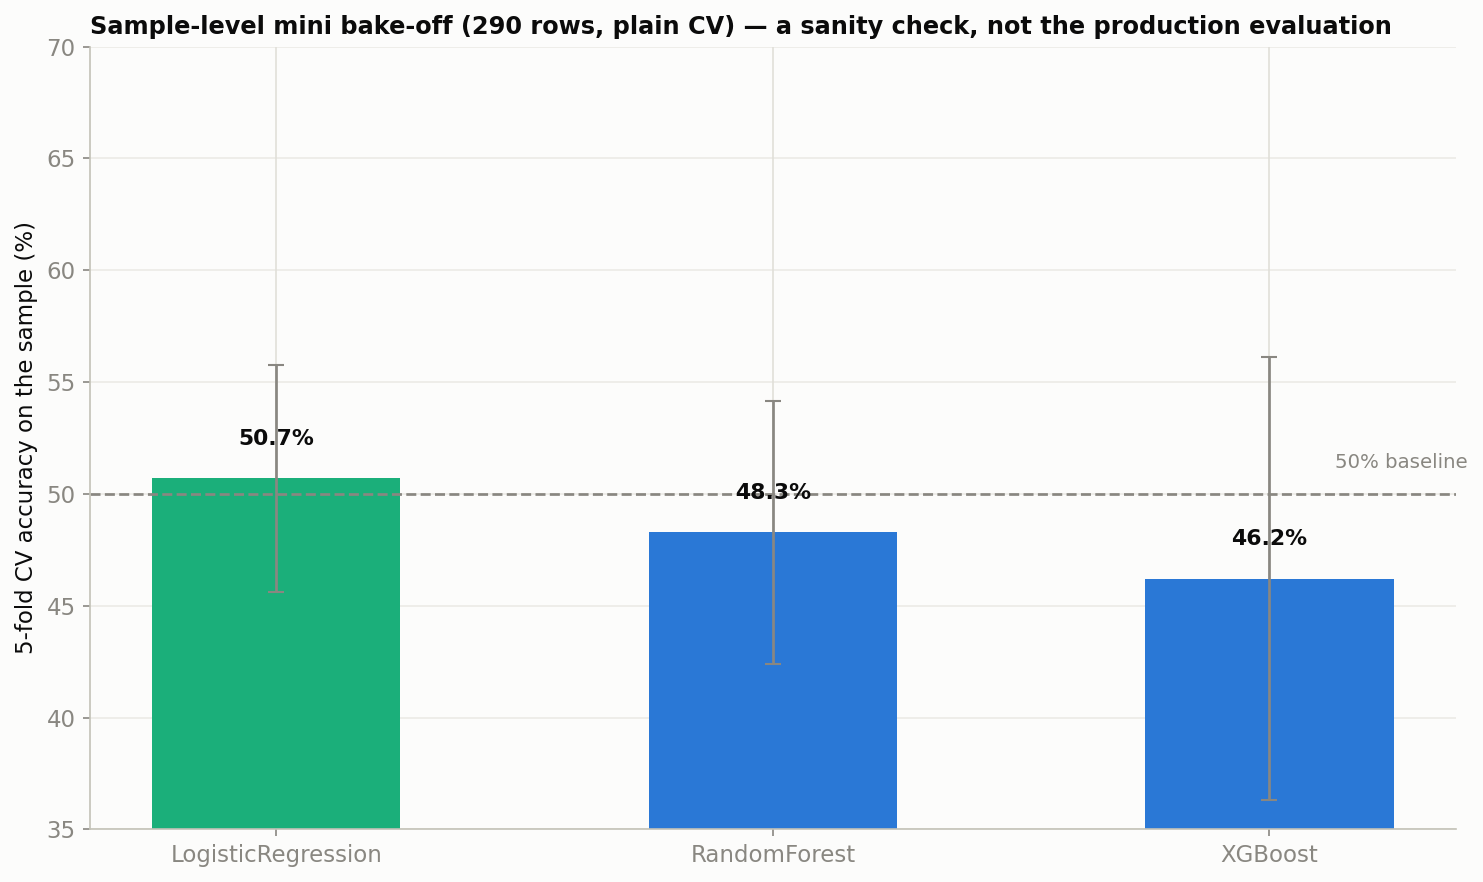

In [6]:
models = {
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    "RandomForest": RandomForestClassifier(n_estimators=300, max_depth=6, random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.9,
                              colsample_bytree=0.9, random_state=SEED, eval_metric="logloss"),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

bakeoff = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    bakeoff[name] = (scores.mean(), scores.std())

fig, ax = plt.subplots(figsize=(10, 6))
names = list(bakeoff.keys())
means = [bakeoff[n][0] * 100 for n in names]
stds = [bakeoff[n][1] * 100 for n in names]
colors = [HIGHLIGHT_COLOR if n == "LogisticRegression" else BLUE for n in names]
bars = ax.bar(names, means, yerr=stds, color=colors, width=0.5,
              error_kw=dict(ecolor=MUTED, elinewidth=1.3, capsize=4))
ax.axhline(50, color=MUTED, linestyle="--", linewidth=1.3)
ax.text(2.4, 51, "50% baseline", color=MUTED, fontsize=9.5, va="bottom", ha="right")
for b, m in zip(bars, means):
    ax.text(b.get_x() + b.get_width() / 2, m + 1.5, f"{m:.1f}%", ha="center", fontsize=10.5, fontweight="bold", color=INK)
ax.set_ylim(35, 70)
ax.set_ylabel("5-fold CV accuracy on the sample (%)")
ax.set_title("Sample-level mini bake-off (290 rows, plain CV) — a sanity check, not the production evaluation",
             loc="left", fontsize=11.5)
style_axes(ax)
fig.tight_layout()
save(fig, "fig04_model_bakeoff")

best_model_name = max(bakeoff, key=lambda k: bakeoff[k][0])
print(f"Best on this sample (plain 5-fold CV): {best_model_name} ({bakeoff[best_model_name][0]*100:.1f}%)")
for n, (m, s) in bakeoff.items():
    print(f"  {n:<20} {m*100:5.1f}% +/- {s*100:4.1f}%")

**What this shows.** Whichever model comes out ahead on this small,
randomly-ordered 290-row sample, that result on its own would not be a
sound basis for choosing a production model — a plain 5-fold CV on a
scattered sample doesn't test whether a model holds up as more history
accumulates, which is exactly what the real walk-forward evaluation is
for. **What it drove.** Nothing on its own; it's shown so the reasoning
above isn't just an unverifiable claim — you can see the sample-level
numbers this notebook actually computed, alongside the documented
production result below.

## Figure 5 — Confusion matrix

*Computed from the sample.* Normalized confusion matrix for
LogisticRegression's cross-validated out-of-fold predictions on the
sample (the production model family, evaluated the same way as the
bake-off above — a CV holdout, not the production walk-forward).

saved ..\assets\fig05_confusion_matrix.png


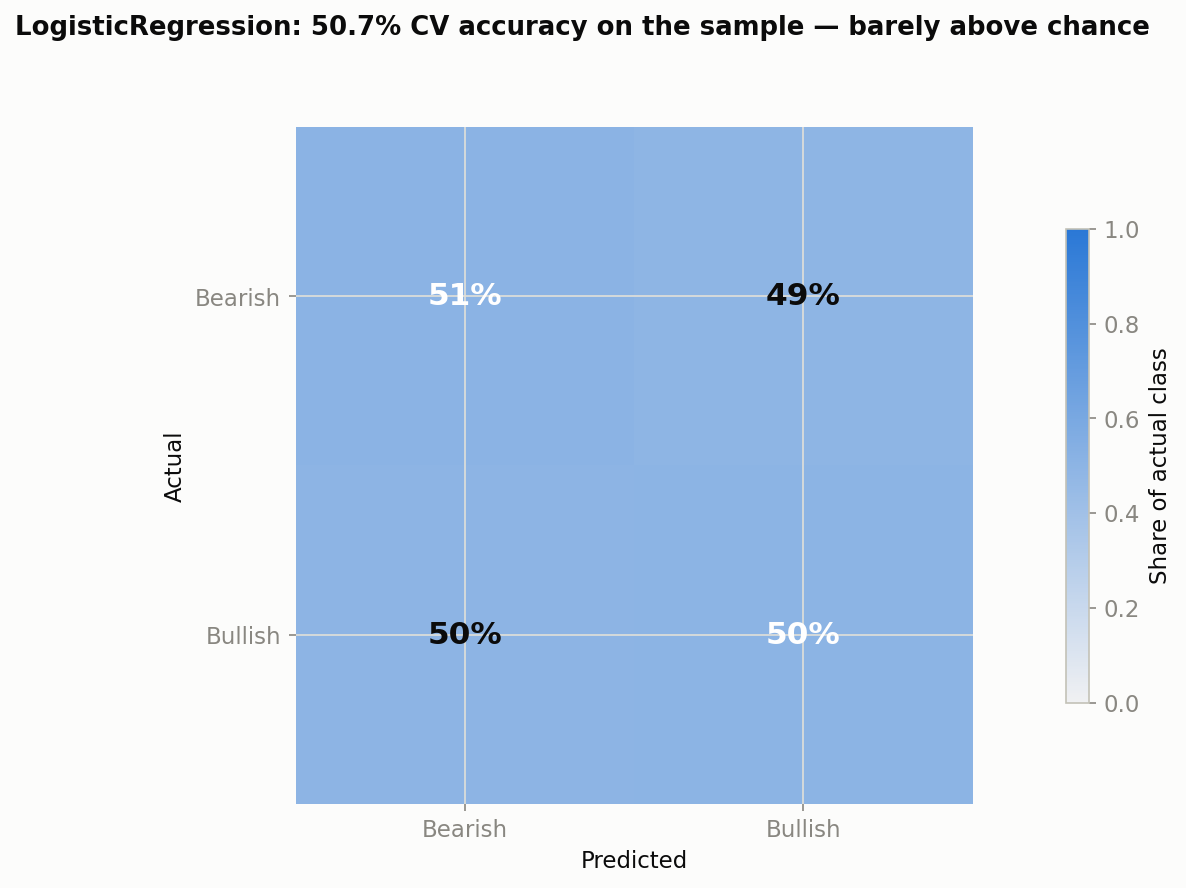

In [7]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
oof_pred = cross_val_predict(logreg, X, y, cv=cv)
acc_sample = accuracy_score(y, oof_pred)
cm = confusion_matrix(y, oof_pred, normalize="true")
labels = ["Bearish", "Bullish"]

fig, ax = plt.subplots(figsize=(8.5, 6))
im = ax.imshow(cm, cmap=sns.light_palette(BLUE, as_cmap=True), vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        txt_color = "white" if cm[i, j] > 0.5 else INK
        ax.text(j, i, f"{cm[i, j]*100:.0f}%", ha="center", va="center", color=txt_color, fontsize=15, fontweight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(labels)
ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
fig.suptitle(f"LogisticRegression: {acc_sample*100:.1f}% CV accuracy on the sample — barely above chance",
             fontsize=12.5, fontweight="bold", x=0.02, ha="left")
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, pad=0.08, label="Share of actual class")
fig.tight_layout(rect=[0, 0, 1, 0.94])
save(fig, "fig05_confusion_matrix")

**What this shows.** LogisticRegression on this sample makes roughly
symmetric mistakes rather than defaulting to one class — consistent with
the balanced label split. **What it drove.** Confirms the sample-level
accuracy above isn't hiding a degenerate one-class predictor.

## Figure 6 — Validation accuracy vs. the 50% baseline

*Reconstructed from documented results, not recomputed from the sample.*
The production model's actual validated accuracy comes from a 10-fold
expanding-window walk-forward, out-of-sample July 2023 – December 2025,
592 out-of-sample trades — a scattered 290-row sample has no valid
chronological order and cannot reproduce this. The point estimate is
**53.5%**; reporting only that number, without an interval, overstates
how settled it is on 592 binary outcomes.

saved ..\assets\fig06_validation_accuracy_ci.png
Documented OOS accuracy: 53.5% (95% Wilson CI: 49.5%-57.5%, n=592)
Distance above 50% baseline in standard deviations: 1.73


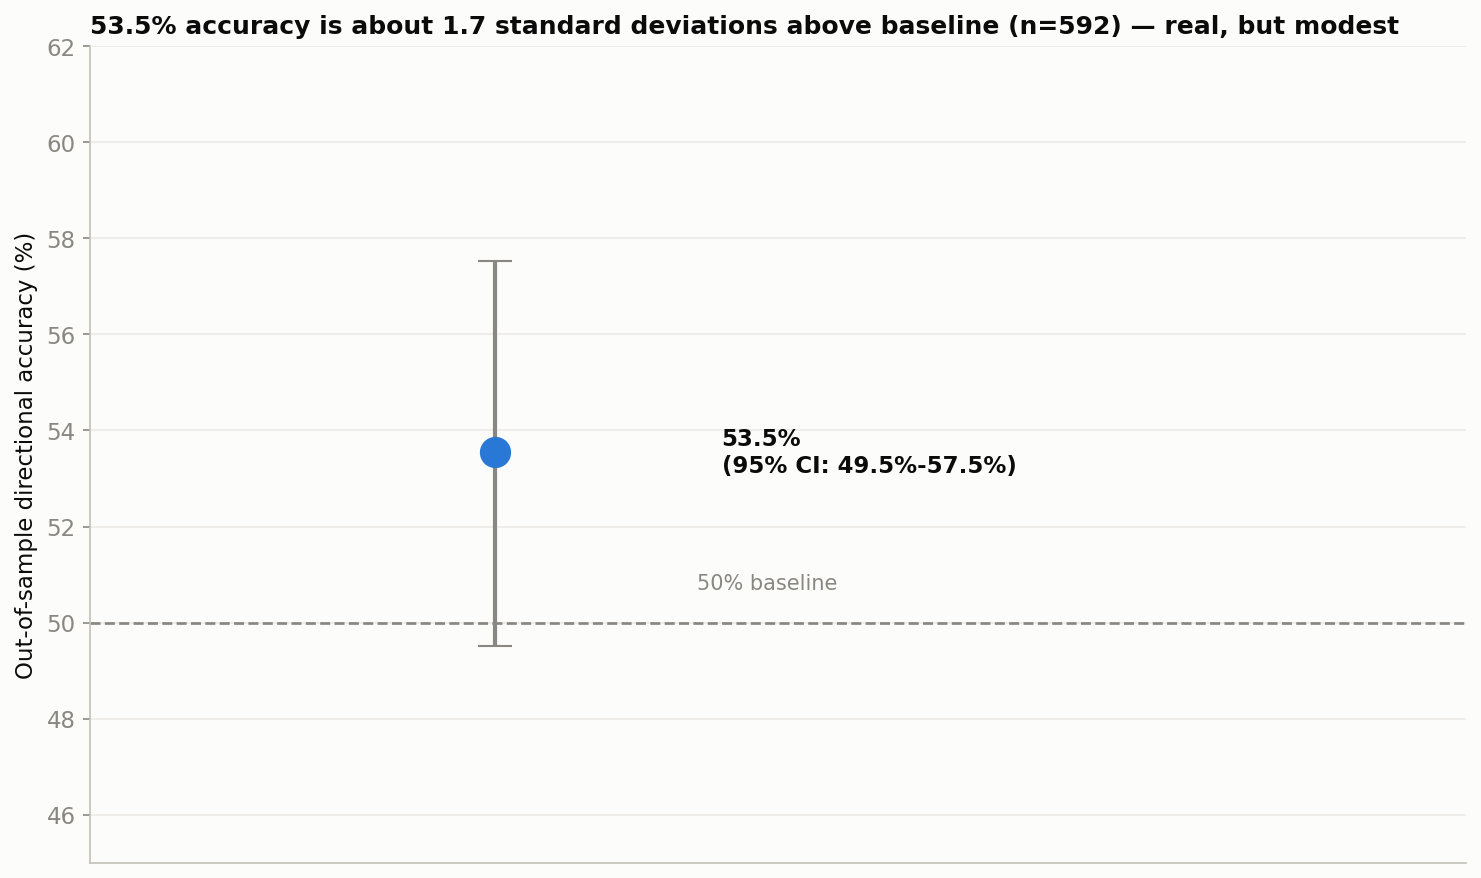

In [8]:
DOCUMENTED_ACCURACY = 0.535
DOCUMENTED_N = 592

lo, mid, hi = wilson_ci(round(DOCUMENTED_ACCURACY * DOCUMENTED_N), DOCUMENTED_N)
z = (mid - 0.5) / np.sqrt(0.5 * 0.5 / DOCUMENTED_N)

fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar([0], [mid * 100], yerr=[[mid * 100 - lo * 100], [hi * 100 - mid * 100]],
            fmt="o", color=BLUE, markersize=14, elinewidth=2, capsize=8, ecolor=MUTED)
ax.axhline(50, color=MUTED, linestyle="--", linewidth=1.3)
ax.text(0.25, 50.6, "50% baseline", color=MUTED, fontsize=10, va="bottom")
ax.annotate(f"{mid*100:.1f}%\n(95% CI: {lo*100:.1f}%-{hi*100:.1f}%)",
            xy=(0, mid * 100), xytext=(0.28, mid * 100), fontsize=11, fontweight="bold", va="center")
ax.set_xlim(-0.5, 1.2)
ax.set_xticks([])
ax.set_ylim(45, 62)
ax.set_ylabel("Out-of-sample directional accuracy (%)")
ax.set_title(f"53.5% accuracy is about {z:.1f} standard deviations above baseline (n={DOCUMENTED_N}) — real, but modest",
             loc="left", fontsize=12)
style_axes(ax)
ax.grid(axis="x")
fig.tight_layout()
save(fig, "fig06_validation_accuracy_ci")

print(f"Documented OOS accuracy: {mid*100:.1f}% (95% Wilson CI: {lo*100:.1f}%-{hi*100:.1f}%, n={DOCUMENTED_N})")
print(f"Distance above 50% baseline in standard deviations: {z:.2f}")

**What this shows.** The 95% confidence interval's lower bound sits just
*under* 50% (49.5%) — meaning this result, on its own, does not statistically
rule out no edge at all at the 95% level, even though the point estimate
(53.5%, ~1.7 standard deviations above chance) is consistent with a real,
modest edge. **What it drove.** This is exactly why the README frames it as
"better than a coin flip, not yet proven decisively so," rather than as a
settled result — the honest reading of this interval is "probably a real
edge, not yet statistically airtight," and position sizing and conviction
should track that, not the point estimate alone.

## Figure 7 — Annualized return

*Reconstructed from documented results, not computed from the sample* (no
rupee figures anywhere in this notebook, matching the README's rule —
only percentage returns and trade counts are reported for this live
strategy). Applying the signal to a futures overlay position and
accounting for realistic trading costs, backtested annualized return
across the 2.5-year walk-forward window was approximately 19% per year,
ranging from about 3% in the weakest half-year to about 26% in the
strongest year. All three calendar years in the window were net positive.

saved ..\assets\fig07_annualized_return_range.png


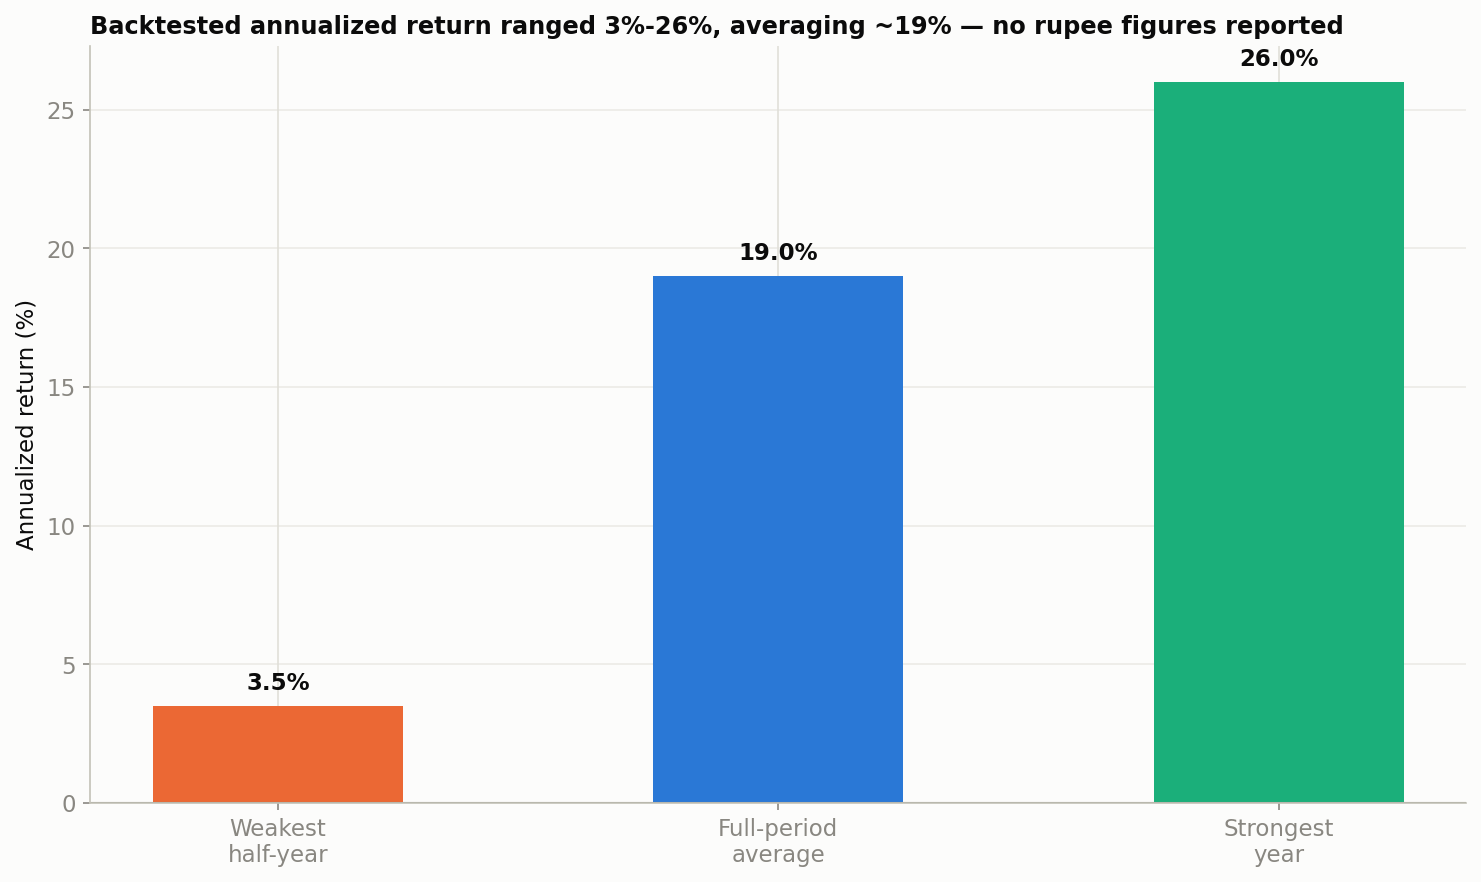

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
years = ["Weakest\nhalf-year", "Full-period\naverage", "Strongest\nyear"]
values = [3.5, 19.0, 26.0]
colors = [ORANGE, BLUE, HIGHLIGHT_COLOR]
bars = ax.bar(years, values, color=colors, width=0.5)
ax.axhline(0, color=MUTED, linewidth=1)
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v:.1f}%", ha="center", fontsize=11, fontweight="bold", color=INK)
ax.set_ylabel("Annualized return (%)")
ax.set_title("Backtested annualized return ranged 3%-26%, averaging ~19% — no rupee figures reported",
             loc="left", fontsize=11.5)
style_axes(ax)
fig.tight_layout()
save(fig, "fig07_annualized_return_range")

**What this shows.** All three calendar years in the walk-forward window
were net positive, but the spread between the weakest and strongest
periods is wide — roughly 3% to 26% — which is more informative than a
single blended average. **What it drove.** Position-sizing decisions
should assume something closer to the weak end of this range is possible
in any given year, not the average.

## What this demonstrates

**The plan.** Overnight positioning across the option chain — how call and
put writers and net delta shift between the previous close and the next
morning — carries some directional information about the following
session. The evidence for that is a real, walk-forward-validated edge
(53.5% accuracy, ~1.7σ above baseline) — modest, not dramatic, but
consistent across 2.5 years and multiple market regimes.

**What would increase conviction:**

- **A longer out-of-sample period.** 592 trades over 2.5 years is enough
  to detect an edge exists, not enough to pin its size down precisely — the
  confidence interval in Figure 6 is still wide relative to the point
  estimate.
- **Live forward-testing**, not just backtesting. Every number in this
  notebook comes from historical data the model (and the researcher) had
  already seen the shape of when the walk-forward was designed. A period
  of genuine forward paper-trading, decided in advance and not revisited,
  is the next real test.
- **Confirming the sample-vs-production disagreement (if any) is benign.**
  If Figure 4's small-sample bake-off disagreed with the production choice
  of LogisticRegression, that's expected from a 290-row random sample and
  not itself concerning — but it's worth periodically re-running the full
  walk-forward as more data accumulates to confirm LogisticRegression is
  still the right choice, rather than assuming a choice made in 2026 stays
  correct indefinitely.
- **Testing performance across VIX regimes.** Like the datashots BTST
  system, this strategy has not been separately evaluated for how it
  behaves when volatility regimes shift meaningfully from what the
  training window saw.